"""
Bootstrap error estimation for TNG50-2 (single-run halo-level bootstrap).

This notebook implements the alternative raised in the paper's "Error
estimation" TODO: with only 5 realizations, a quoted +-3sigma (or even the
full range, see 10_variance_TNG50_2.ipynb) is itself noisy. Instead, we
bootstrap the *single* run0 637-halo TNG50-2 catalog: resample halo_id with
replacement, independently within each mass-bin stratum (matching the
original stratified sampling design), 1000 times, and take the 16-84th
percentile of the resulting statistic as the band. No new skewers are
needed -- this reuses the existing run0 pickle.

Because the exhaustive top mass bin (37 halos, all of them used in every
realization) has *zero* across-run scatter in the 5-realization approach,
this also gives that bin a genuine, non-degenerate uncertainty band for the
first time: bootstrap resampling of a fixed finite set still produces real
sampling variance.
"""


In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import matplotlib.patches as patches


# ==============================================================================
# CELL: CONFIGURATION & STYLE
# ==============================================================================
def matplotlib_default_config():
    """Returns the default dictionary configurations for publication-ready plots."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew

%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


In [3]:
# ==============================================================================
# CELL: PATHS -- load ONLY run0 (the single 637-halo TNG50-2 catalog)
# ==============================================================================
from pathlib import Path

PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())

DATA_DIR = PROJ_ROOT / "data_TNG50-2_snap025_5runs_peak_plus_blend"
RUN0_FILE = DATA_DIR / "TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl"

print("project :", PROJ_ROOT)
print("run0    :", RUN0_FILE, "| exists:", RUN0_FILE.exists())


project : /home/vroberto/FakeSpectra_DLAs
run0    : /home/vroberto/FakeSpectra_DLAs/data_TNG50-2_snap025_5runs_peak_plus_blend/TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl | exists: True


In [4]:
# ==============================================================================
# CELL: LOAD run0 & APPLY THE SAME TAU FIX AS 10_variance_TNG50_2.ipynb
# ==============================================================================
APPLY_TAU_FIX = True
TAU_FIX = 8.0 / 7.0
HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H

df0 = pd.read_pickle(RUN0_FILE)
df0['r_mult_round'] = df0['r_multiplier'].round(2)

if APPLY_TAU_FIX and not df0.attrs.get('tau_fixed', False):
    df0['flux'] = [np.asarray(f, float) ** TAU_FIX for f in df0['flux']]
    df0.attrs['tau_fixed'] = True

if 'halo_mass_msun' not in df0.columns:
    df0['halo_mass_msun'] = df0['halo_mass'] * MASS_CONVERSION_FACTOR

unique_radii = np.sort(df0['r_mult_round'].unique())
n_halos = df0['halo_id'].nunique()

print(f"run0: {len(df0):,} skewer rows, {n_halos} halos, "
      f"{len(unique_radii)} impact parameters")


run0: 231,231 skewer rows, 637 halos, 29 impact parameters


In [5]:
# ==============================================================================
# CELL: GRID DATA & GLOBAL (COSMIC-MEAN) FRACTIONS -- unchanged reference
# ==============================================================================
grid_file_path = 'data_grid/TNG50-2_z3_Grid_500x500_DLAMode.pkl'

df_grid = pd.read_pickle(grid_file_path)

bins_grid   = [0, 1.6e17, 1e19, 2e20, 1e21, np.inf]
labels_grid = ['Forest', 'LLS', 'Sub_DLA', 'Small_DLA', 'Large_DLA']

df_grid['category'] = pd.cut(
    df_grid['total_col_den'], bins=bins_grid, labels=labels_grid, right=False
)

total_grid_skewers = len(df_grid)
grid_counts    = df_grid['category'].value_counts(sort=False)
grid_fractions = grid_counts / total_grid_skewers

print(f"Grid Data Processed: {total_grid_skewers:,} skewers.")


Grid Data Processed: 750,000 skewers.


In [6]:
# ==============================================================================
# CELL: CATEGORY STYLES, MASS BINS, HISTOGRAM GRID
# ==============================================================================
cat_styles = {
    'Large_DLA': {'color': 'indigo',       'marker': 'v',
                  'label': r'Large DLA ($\log N_{\mathrm{HI}} \geq 21.0$)'},
    'Small_DLA': {'color': 'darkred',      'marker': 'o',
                  'label': r'Small DLA ($20.3 \leq \log N_{\mathrm{HI}} < 21.0$)'},
    'Sub_DLA':   {'color': 'darkorange',   'marker': 's',
                  'label': r'Sub-DLA ($19.0 \leq \log N_{\mathrm{HI}} < 20.3$)'},
    'LLS':       {'color': 'forestgreen',  'marker': '^',
                  'label': r'LLS ($17.2 \leq \log N_{\mathrm{HI}} < 19.0$)'},
    'Forest':    {'color': 'midnightblue', 'marker': 'D',
                  'label': r'Ly-$\alpha$ Forest ($\log N_{\mathrm{HI}} < 17.2$)'},
}
CATS = list(cat_styles.keys())   # fixes the column order used everywhere below

# pd.cut needs increasing edges; CATS above is just the display/stacking order
CAT_BIN_EDGES  = [-np.inf, 17.2, 19.0, 20.3, 21.0, np.inf]
CAT_BIN_LABELS = ['Forest', 'LLS', 'Sub_DLA', 'Small_DLA', 'Large_DLA']

mass_edges = [10**10.0, 10**10.5, 10**11.0, 10**11.5, 10**12.0, 10**13.0]
mass_bin_titles = [
    r'$10^{10.0}$–$10^{10.5}\,M_\odot$',
    r'$10^{10.5}$–$10^{11.0}\,M_\odot$',
    r'$10^{11.0}$–$10^{11.5}\,M_\odot$',
    r'$10^{11.5}$–$10^{12.0}\,M_\odot$',
    r'$10^{12.0}$–$10^{13.0}\,M_\odot$',
]
n_mass_bins = len(mass_bin_titles)

# Fine log N_HI grid for the ridgeline (same range/resolution as the main notebook)
NUM_HIST_BINS = 100
hist_bins = np.linspace(16.0, 23.0, NUM_HIST_BINS + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2
bin_width = hist_bins[1] - hist_bins[0]

N_BOOT = 1000
BOOT_SEED = 0
PCT_LO, PCT_HI = 16, 84   # bootstrap percentile band, matches a 1sigma-equivalent CI


In [7]:
# ==============================================================================
# CELL: PER-HALO COUNT TABLES (the core data structure the bootstrap resamples)
# ==============================================================================
# For every halo, every impact parameter and every absorber class we count how
# many of that halo's skewers fall in that class. Bootstrapping halo_id with
# replacement and re-summing these counts is equivalent to re-running the
# whole covering-fraction / ridgeline pipeline on a resampled halo catalogue,
# without touching a single skewer.

def build_halo_arrays(df, mass_edges, radii, cats, cat_edges, cat_labels, hist_bins):
    df = df.copy()
    df['category'] = pd.cut(df['log_n_hi'], bins=cat_edges, labels=cat_labels)

    radius_index = {b: i for i, b in enumerate(radii)}
    cat_index    = {c: i for i, c in enumerate(cats)}
    n_radii = len(radii)
    n_cat   = len(cats)
    n_hist  = len(hist_bins) - 1

    df['_radius_idx'] = df['r_mult_round'].map(radius_index)
    df['_cat_idx']    = df['category'].map(cat_index)

    # Only genuine HCD detections carry a meaningful log_n_hi for the ridgeline;
    # the pipeline forces sub-threshold skewers to log_n_hi = 0.0 (see
    # 10_variance_TNG50_2.ipynb, ridgeline cell).
    valid = (df['log_n_hi'] > 1.0).values
    hist_idx = np.full(len(df), -1, dtype=np.int32)
    hist_idx[valid] = np.clip(
        np.digitize(df.loc[valid, 'log_n_hi'].values, hist_bins) - 1, 0, n_hist - 1
    )
    df['_hist_idx'] = hist_idx

    halo_mass = df.groupby('halo_id')['halo_mass_msun'].first()
    halo_bin  = pd.cut(halo_mass, bins=mass_edges, labels=False, include_lowest=True)

    bins_data = []
    for m in range(len(mass_edges) - 1):
        ids = halo_bin[halo_bin == m].index.values
        cat_counts  = np.zeros((len(ids), n_radii, n_cat),  dtype=np.int16)
        hist_counts = np.zeros((len(ids), n_radii, n_hist), dtype=np.int16)

        if len(ids) > 0:
            sub = df[df['halo_id'].isin(ids)]
            id_index = {h: i for i, h in enumerate(ids)}
            h_idx = sub['halo_id'].map(id_index).values

            np.add.at(cat_counts, (h_idx, sub['_radius_idx'].values, sub['_cat_idx'].values), 1)

            valid_sub = sub[sub['_hist_idx'].values >= 0]
            vh_idx = valid_sub['halo_id'].map(id_index).values
            np.add.at(hist_counts, (vh_idx, valid_sub['_radius_idx'].values, valid_sub['_hist_idx'].values), 1)

        bins_data.append({'ids': ids, 'cat_counts': cat_counts, 'hist_counts': hist_counts})

    return bins_data


bins_data_all = build_halo_arrays(
    df0, mass_edges, unique_radii, CATS, CAT_BIN_EDGES, CAT_BIN_LABELS, hist_bins
)

for m, bd in enumerate(bins_data_all):
    print(f"  mass bin {m} ({mass_bin_titles[m]}): {len(bd['ids'])} halos")


  mass bin 0 ($10^{10.0}$–$10^{10.5}\,M_\odot$): 150 halos
  mass bin 1 ($10^{10.5}$–$10^{11.0}\,M_\odot$): 150 halos
  mass bin 2 ($10^{11.0}$–$10^{11.5}\,M_\odot$): 150 halos
  mass bin 3 ($10^{11.5}$–$10^{12.0}\,M_\odot$): 150 halos
  mass bin 4 ($10^{12.0}$–$10^{13.0}\,M_\odot$): 37 halos


In [8]:
# ==============================================================================
# CELL: BOOTSTRAP ENGINE
# ==============================================================================
def bootstrap_cat_counts(bins_data, n_boot=N_BOOT, seed=BOOT_SEED):
    """(n_boot, n_radii, n_cat) totals from resampling halo_id within each
    mass-bin stratum independently, n_boot times, and summing counts."""
    n_radii, n_cat = bins_data[0]['cat_counts'].shape[1:]
    rng = np.random.default_rng(seed)
    boot_totals = np.zeros((n_boot, n_radii, n_cat), dtype=np.int64)
    for bd in bins_data:
        n_h = len(bd['ids'])
        if n_h == 0:
            continue
        draw = rng.integers(0, n_h, size=(n_boot, n_h))
        boot_totals += bd['cat_counts'][draw].sum(axis=1)
    return boot_totals


def fractions_from_totals(cat_totals):
    """cat_totals: (..., n_cat) -> fractions (..., n_cat), NaN where empty."""
    denom = cat_totals.sum(axis=-1, keepdims=True)
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(denom > 0, cat_totals / denom, np.nan)


def point_estimate_fractions(bins_data):
    """The actual run0 fraction (no resampling) -- used as the central line."""
    total = sum(bd['cat_counts'].sum(axis=0) for bd in bins_data)  # (n_radii, n_cat)
    return fractions_from_totals(total)


def bootstrap_bands(bins_data, n_boot=N_BOOT, seed=BOOT_SEED, pct=(PCT_LO, PCT_HI)):
    boot_totals = bootstrap_cat_counts(bins_data, n_boot=n_boot, seed=seed)
    boot_fracs  = fractions_from_totals(boot_totals)
    lo = np.nanpercentile(boot_fracs, pct[0], axis=0)
    hi = np.nanpercentile(boot_fracs, pct[1], axis=0)
    central = point_estimate_fractions(bins_data)
    return {'central': central, 'lo': lo, 'hi': hi, 'boot_fracs': boot_fracs}


def bootstrap_ridgeline(bins_data, n_boot=N_BOOT, seed=BOOT_SEED + 1, chunk=250):
    """Bootstrap the ridgeline density and the forest fraction together, using
    the SAME resample draw per stratum per iteration so the two stay
    consistent within a replicate. Chunked over n_boot to bound memory."""
    n_radii, n_hist = bins_data[0]['hist_counts'].shape[1:]
    n_cat = bins_data[0]['cat_counts'].shape[2]
    rng = np.random.default_rng(seed)

    boot_hist = np.zeros((n_boot, n_radii, n_hist), dtype=np.int64)
    boot_cat  = np.zeros((n_boot, n_radii, n_cat),  dtype=np.int64)

    for start in range(0, n_boot, chunk):
        end = min(start + chunk, n_boot)
        m = end - start
        for bd in bins_data:
            n_h = len(bd['ids'])
            if n_h == 0:
                continue
            draw = rng.integers(0, n_h, size=(m, n_h))
            boot_hist[start:end] += bd['hist_counts'][draw].sum(axis=1)
            boot_cat[start:end]  += bd['cat_counts'][draw].sum(axis=1)

    total = boot_cat.sum(axis=2)  # (n_boot, n_radii)
    with np.errstate(invalid='ignore', divide='ignore'):
        density = np.where(total[:, :, None] > 0,
                            boot_hist / (total[:, :, None] * bin_width), np.nan)
    forest_idx = CATS.index('Forest')
    with np.errstate(invalid='ignore', divide='ignore'):
        forest_pct = np.where(total > 0, boot_cat[:, :, forest_idx] / total * 100, np.nan)
    return density, forest_pct


def point_estimate_ridgeline(bins_data):
    hist_total = sum(bd['hist_counts'].sum(axis=0) for bd in bins_data)  # (n_radii, n_hist)
    cat_total  = sum(bd['cat_counts'].sum(axis=0) for bd in bins_data)   # (n_radii, n_cat)
    total = cat_total.sum(axis=1)
    with np.errstate(invalid='ignore', divide='ignore'):
        density = np.where(total[:, None] > 0, hist_total / (total[:, None] * bin_width), np.nan)
    forest_idx = CATS.index('Forest')
    with np.errstate(invalid='ignore', divide='ignore'):
        forest_pct = np.where(total > 0, cat_total[:, forest_idx] / total * 100, np.nan)
    return density, forest_pct


/tmp/ipykernel_168497/1255997368.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


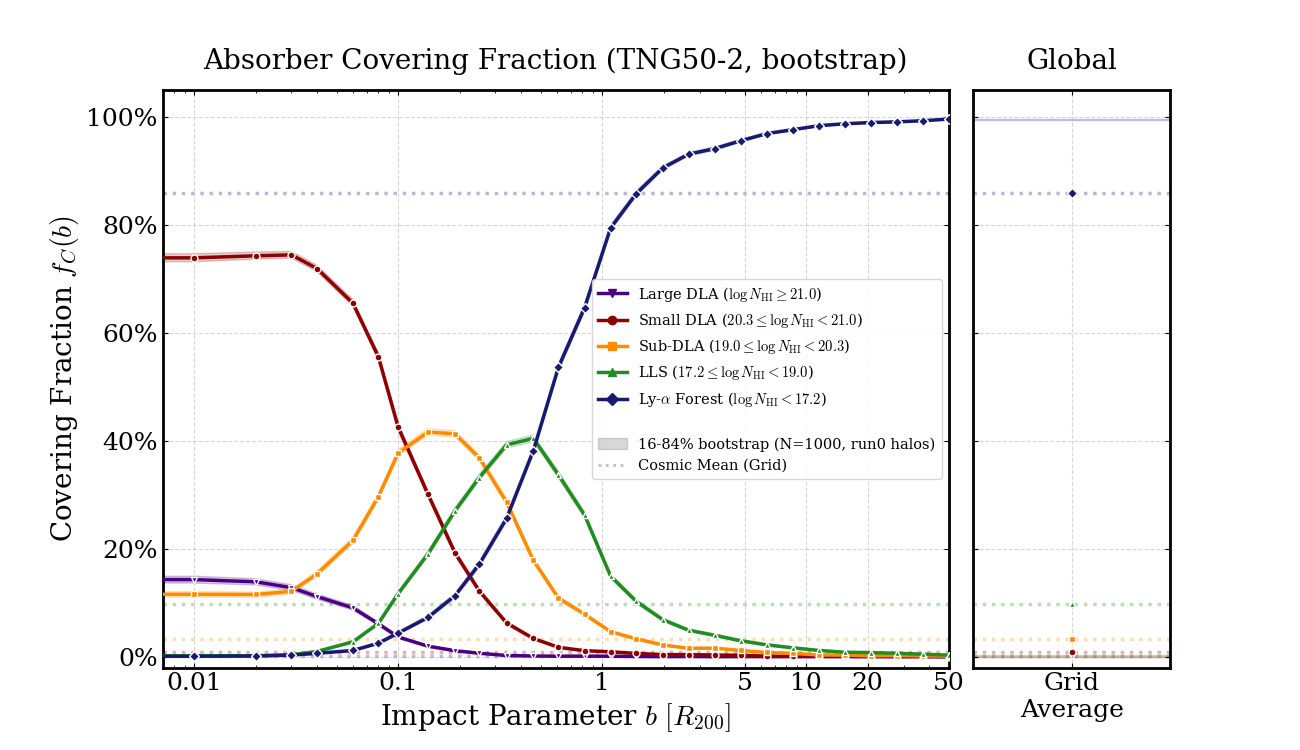

In [9]:
# ==============================================================================
# CELL: COMBINED PLOT -- ALL MASSES, BOOTSTRAP 16-84% BAND, + GRID SIDE PANEL
# ==============================================================================
bands_all = bootstrap_bands(bins_data_all)

fig, (ax_main, ax_grid) = plt.subplots(
    1, 2, figsize=(13, 7.5), sharey=True,
    gridspec_kw={'width_ratios': [4, 1], 'wspace': 0.05},
)

for j, (cat, style) in enumerate(cat_styles.items()):
    central = bands_all['central'][:, j]
    lo      = bands_all['lo'][:, j]
    hi      = bands_all['hi'][:, j]

    ax_main.fill_between(unique_radii, lo, hi, color=style['color'], alpha=0.20, zorder=1)
    ax_main.plot(
        unique_radii, central,
        color=style['color'], lw=2.5, ls='-',
        marker=style['marker'], ms=5, mec='white', zorder=3,
    )

x_pos_grid = 1.0
for j, (cat, style) in enumerate(cat_styles.items()):
    grid_val = grid_fractions[cat]
    last_lo, last_hi = bands_all['lo'][-1, j], bands_all['hi'][-1, j]

    ax_grid.axhspan(last_lo, last_hi, color=style['color'], alpha=0.20, zorder=1)
    ax_grid.plot(x_pos_grid, grid_val, color=style['color'], marker=style['marker'],
                 ms=5, mec='white', zorder=3)

    ax_main.axhline(grid_val, color=style['color'], ls=':', alpha=0.3, zorder=0)
    ax_grid.axhline(grid_val, color=style['color'], ls=':', alpha=0.3, zorder=0)

ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))
ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])
ax_main.set_xlim(unique_radii[unique_radii > 0].min() * 0.7, 50)
ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(r'Absorber Covering Fraction (TNG50-2, bootstrap)', pad=15)

ax_grid.grid(True, ls='--', alpha=0.5)
ax_grid.set_xlim(0.8, 1.2)
ax_grid.set_xticks([x_pos_grid])
ax_grid.set_xticklabels(['Grid\nAverage'])
ax_grid.set_title('Global', pad=15)

legend_elements = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], label=c['label'])
    for c in cat_styles.values()
]
legend_elements.append(Line2D([0], [0], color='none', label=' '))
legend_elements.append(
    patches.Patch(facecolor='gray', alpha=0.3, edgecolor='gray',
                  label=rf'{PCT_LO}-{PCT_HI}% bootstrap (N={N_BOOT}, run0 halos)')
)
legend_elements.append(Line2D([0], [0], color='gray', ls=':', alpha=0.5, lw=2, label='Cosmic Mean (Grid)'))

ax_main.legend(handles=legend_elements, loc='center right', frameon=True,
               fontsize=10.5, edgecolor='lightgray', facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


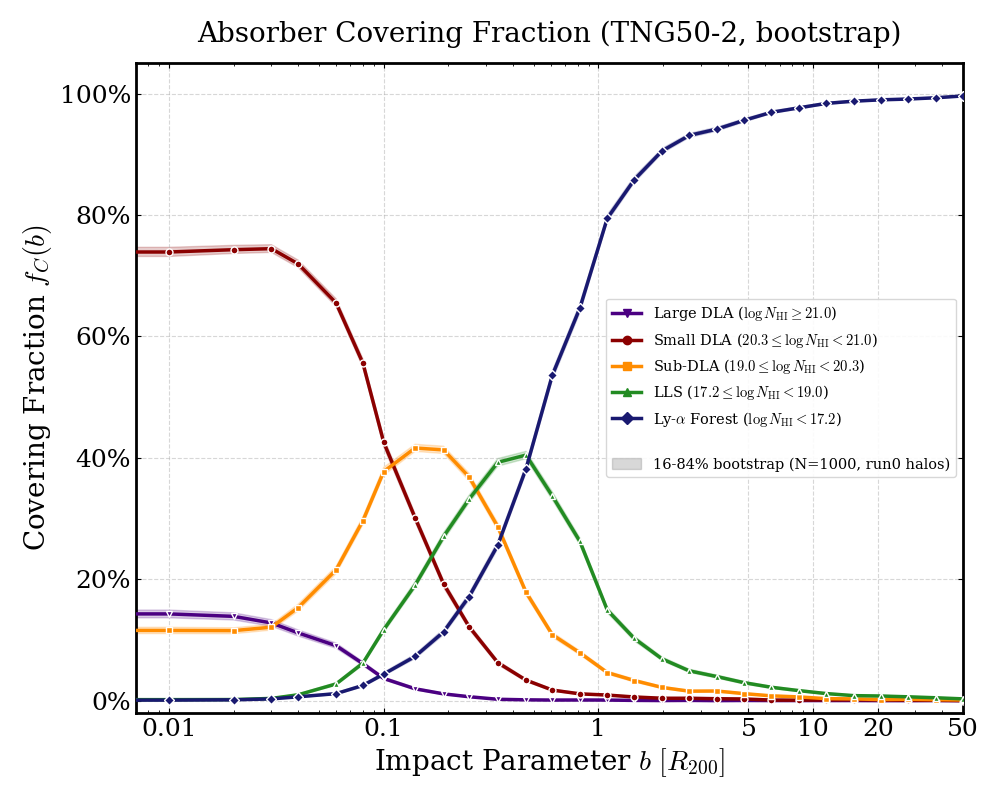

In [10]:
# Plot without the side panel for better visibility of the main panel!
# ==============================================================================
# CELL: COVERING FRACTION PROFILE ONLY (BOOTSTRAP 16-84% BAND)
# ==============================================================================
fig, ax_main = plt.subplots(figsize=(10, 8))

for j, (cat, style) in enumerate(cat_styles.items()):
    central = bands_all['central'][:, j]
    lo      = bands_all['lo'][:, j]
    hi      = bands_all['hi'][:, j]

    ax_main.fill_between(unique_radii, lo, hi, color=style['color'], alpha=0.20, zorder=1)
    ax_main.plot(
        unique_radii, central,
        color=style['color'], lw=2.5, ls='-',
        marker=style['marker'], ms=5, mec='white', zorder=3,
    )

ax_main.grid(True, ls='--', alpha=0.5)
ax_main.set_xscale('log')
ax_main.set_ylim(-0.02, 1.05)
ax_main.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))
ax_main.set_xticks([0.01, 0.1, 1.0, 5.0, 10.0, 20.0, 50.0])
ax_main.set_xticklabels(['0.01', '0.1', '1', '5', '10', '20', '50'])
ax_main.set_xlim(unique_radii[unique_radii > 0].min() * 0.7, 50)
ax_main.set_xlabel(r'Impact Parameter $b \ [R_{200}]$')
ax_main.set_ylabel(r'Covering Fraction $f_C(b)$')
ax_main.set_title(r'Absorber Covering Fraction (TNG50-2, bootstrap)', pad=15)

legend_elements = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], label=c['label'])
    for c in cat_styles.values()
]
legend_elements.append(Line2D([0], [0], color='none', label=' '))
legend_elements.append(
    patches.Patch(facecolor='gray', alpha=0.3, edgecolor='gray',
                  label=rf'{PCT_LO}-{PCT_HI}% bootstrap (N={N_BOOT}, run0 halos)')
)

ax_main.legend(handles=legend_elements, loc='center right', frameon=True,
               fontsize=10.5, edgecolor='lightgray', facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


# Ridgeline Plot! (bootstrap band)

In [11]:
# ==============================================================================
# CELL: RIDGELINE -- BOOTSTRAP BAND (DENSITY-NORMALIZED, ALIGNED EDGES)
# ==============================================================================
SELECTED_B = sorted(unique_radii[unique_radii >= 0.0])
SELECTED_B = [b for b in SELECTED_B if b <= 2.0]
sel_idx    = [int(np.where(unique_radii == b)[0][0]) for b in SELECTED_B]
n_sel      = len(SELECTED_B)
print(f"Impact parameters for ridgeline ({n_sel}):\n  {SELECTED_B}")

# Same categorical background colours as 10_variance_TNG50_2.ipynb
c_forest, c_lls, c_subdla, c_smalldla, c_largedla = (
    '#E3F2FD', '#E8F5E9', '#FFF3E0', '#FFCDD2', '#E1BEE7'
)
overlap_factor = 1.8   # cosmetic vertical scaling only; areas are unaffected


def bins_data_sliced(bins_data, idx):
    """Restrict every halo's per-radius arrays to the ridgeline's impact
    parameters, so the bootstrap only pays for the radii actually plotted."""
    return [
        {'ids': bd['ids'],
         'cat_counts': bd['cat_counts'][:, idx, :],
         'hist_counts': bd['hist_counts'][:, idx, :]}
        for bd in bins_data
    ]


def paint_ridgeline_bootstrap(ax, bins_data, sel_idx, selected_b, title_text='', show_legend=True):
    sliced = bins_data_sliced(bins_data, sel_idx)
    density_central, forest_central = point_estimate_ridgeline(sliced)
    density_boot, forest_boot       = bootstrap_ridgeline(sliced)
    density_lo = np.nanpercentile(density_boot, PCT_LO, axis=0)
    density_hi = np.nanpercentile(density_boot, PCT_HI, axis=0)
    forest_lo  = np.nanpercentile(forest_boot, PCT_LO, axis=0)
    forest_hi  = np.nanpercentile(forest_boot, PCT_HI, axis=0)

    ax.axvspan(16.0, 17.2, color=c_forest,   zorder=0)
    ax.axvspan(17.2, 19.0, color=c_lls,      zorder=0)
    ax.axvspan(19.0, 20.3, color=c_subdla,   zorder=0)
    ax.axvspan(20.3, 21.0, color=c_smalldla, zorder=0)
    ax.axvspan(21.0, 23.0, color=c_largedla, zorder=0)
    for xv in [17.2, 19.0, 20.3, 21.0]:
        ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

    text_y_pos = 0.98
    bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7, edgecolor="none")
    for xv, label in [(16.60, r'Ly-$\alpha$ Forest'), (18.10, 'LLS'), (19.65, 'Sub-DLA'),
                       (20.65, 'Small-DLA'), (22.00, 'Large-DLA')]:
        ax.text(xv, text_y_pos, label, transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)

    ax.grid(axis='x', ls=':', alpha=0.4)
    ax.grid(axis='y', visible=False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    y_ticks, y_labels = [], []
    for i_b, b_val in enumerate(selected_b):
        y_base = i_b
        y_ticks.append(y_base)
        y_labels.append(f"{b_val:.2f}")
        ax.axhline(y_base, color='gray', lw=0.8, alpha=0.3, zorder=1)

        lo_scaled      = density_lo[i_b] * overlap_factor
        hi_scaled      = density_hi[i_b] * overlap_factor
        central_scaled = density_central[i_b] * overlap_factor

        ax.fill_between(x_hist, y_base + lo_scaled, y_base + hi_scaled,
                         color='gray', alpha=0.20, zorder=i_b + 4)
        ax.plot(x_hist, y_base + central_scaled, color='black', lw=1.6, ls='-', zorder=i_b + 6)

        ax.text(
            16.1, y_base + 0.15,
            rf"{forest_central[i_b]:.0f}% [{forest_lo[i_b]:.0f}-{forest_hi[i_b]:.0f}]",
            color='black', fontsize=13, fontweight='bold', zorder=20,
        )

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels, fontsize=9)
    ax.set_xlim(16.0, 23.0)
    ax.set_ylim(-0.5, len(selected_b) - 1 + overlap_factor + 0.5)

    if title_text:
        ax.text(0.98, 0.90, title_text, transform=ax.transAxes, fontsize=13, ha='right', va='top',
                bbox=dict(facecolor='white', alpha=0.9, edgecolor='none'), zorder=30)

    if show_legend:
        central_line = Line2D([0], [0], color='black', lw=1.6, label='run0 (point estimate)')
        band_patch = patches.Patch(facecolor='gray', alpha=0.25, edgecolor='gray',
                                    label=rf'{PCT_LO}-{PCT_HI}% bootstrap (N={N_BOOT})')
        leg = ax.legend(handles=[central_line, band_patch], loc='upper right',
                         frameon=True, fontsize=13, bbox_to_anchor=(0.99, 0.85),
                         facecolor='white', framealpha=0.95, edgecolor='darkgray')
        leg.set_zorder(100)


Impact parameters for ridgeline (18):
  [0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


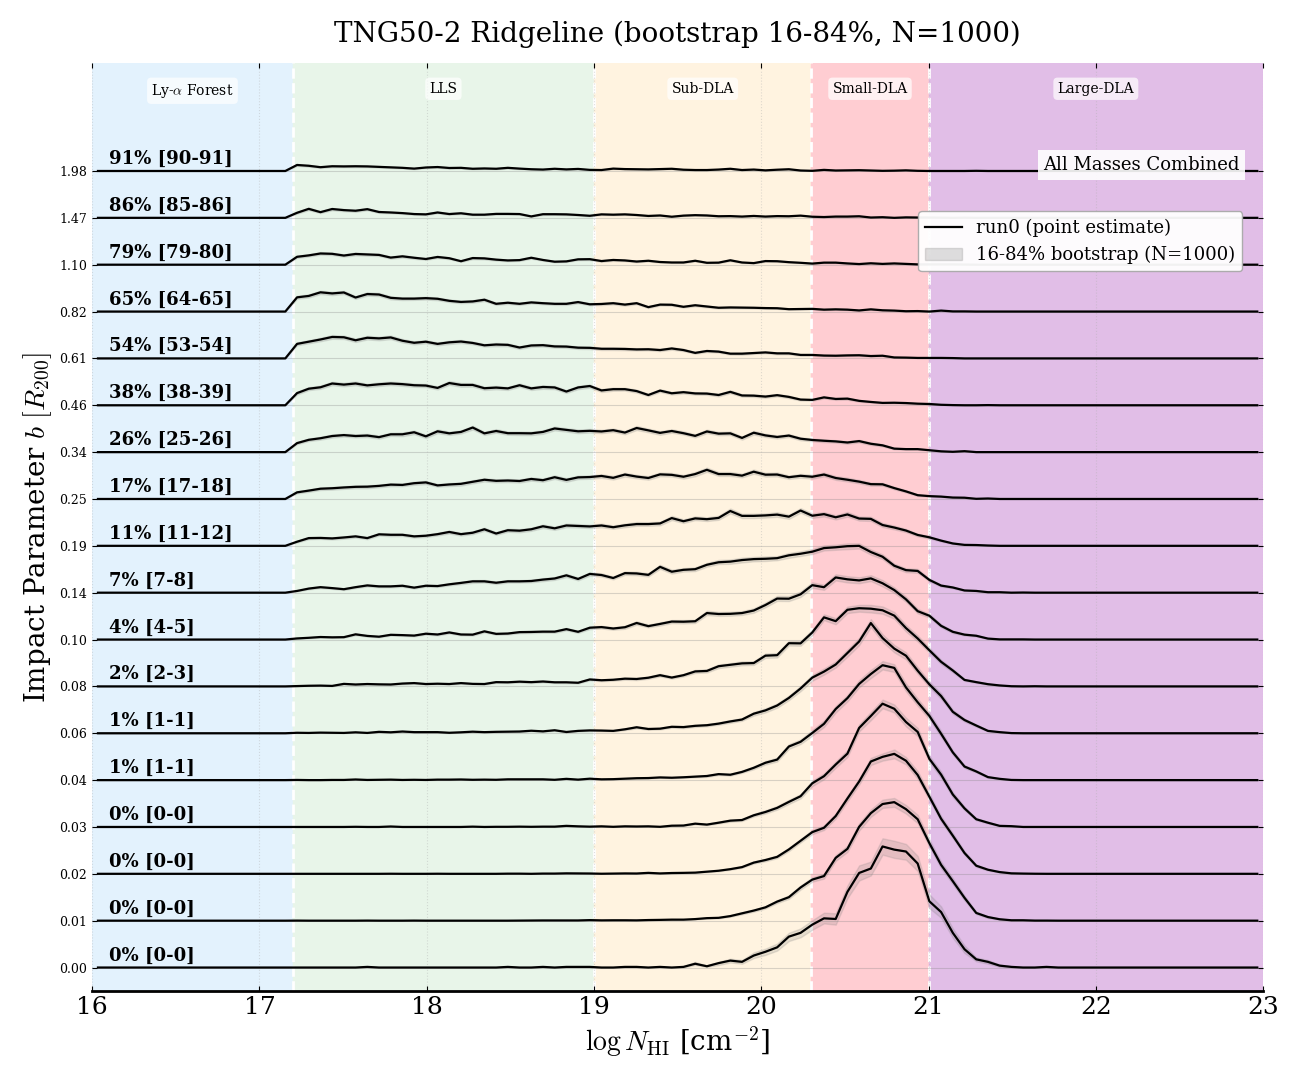

In [12]:
# ==========================================================================
# PLOT: RIDGELINE -- ALL MASSES COMBINED (bootstrap band)
# ==========================================================================
fig_height_all = max(8, 0.60 * n_sel)
fig_all, ax_all = plt.subplots(figsize=(13, fig_height_all))

paint_ridgeline_bootstrap(
    ax_all, bins_data_all, sel_idx, SELECTED_B,
    title_text='All Masses Combined', show_legend=True,
)

ax_all.set_xlabel(r"$\log N_{\rm HI}$ [cm$^{-2}$]")
ax_all.set_ylabel(r'Impact Parameter $b \ [R_{200}]$')
ax_all.set_title(rf'TNG50-2 Ridgeline (bootstrap {PCT_LO}-{PCT_HI}%, N={N_BOOT})', pad=15)

plt.tight_layout()
plt.show()


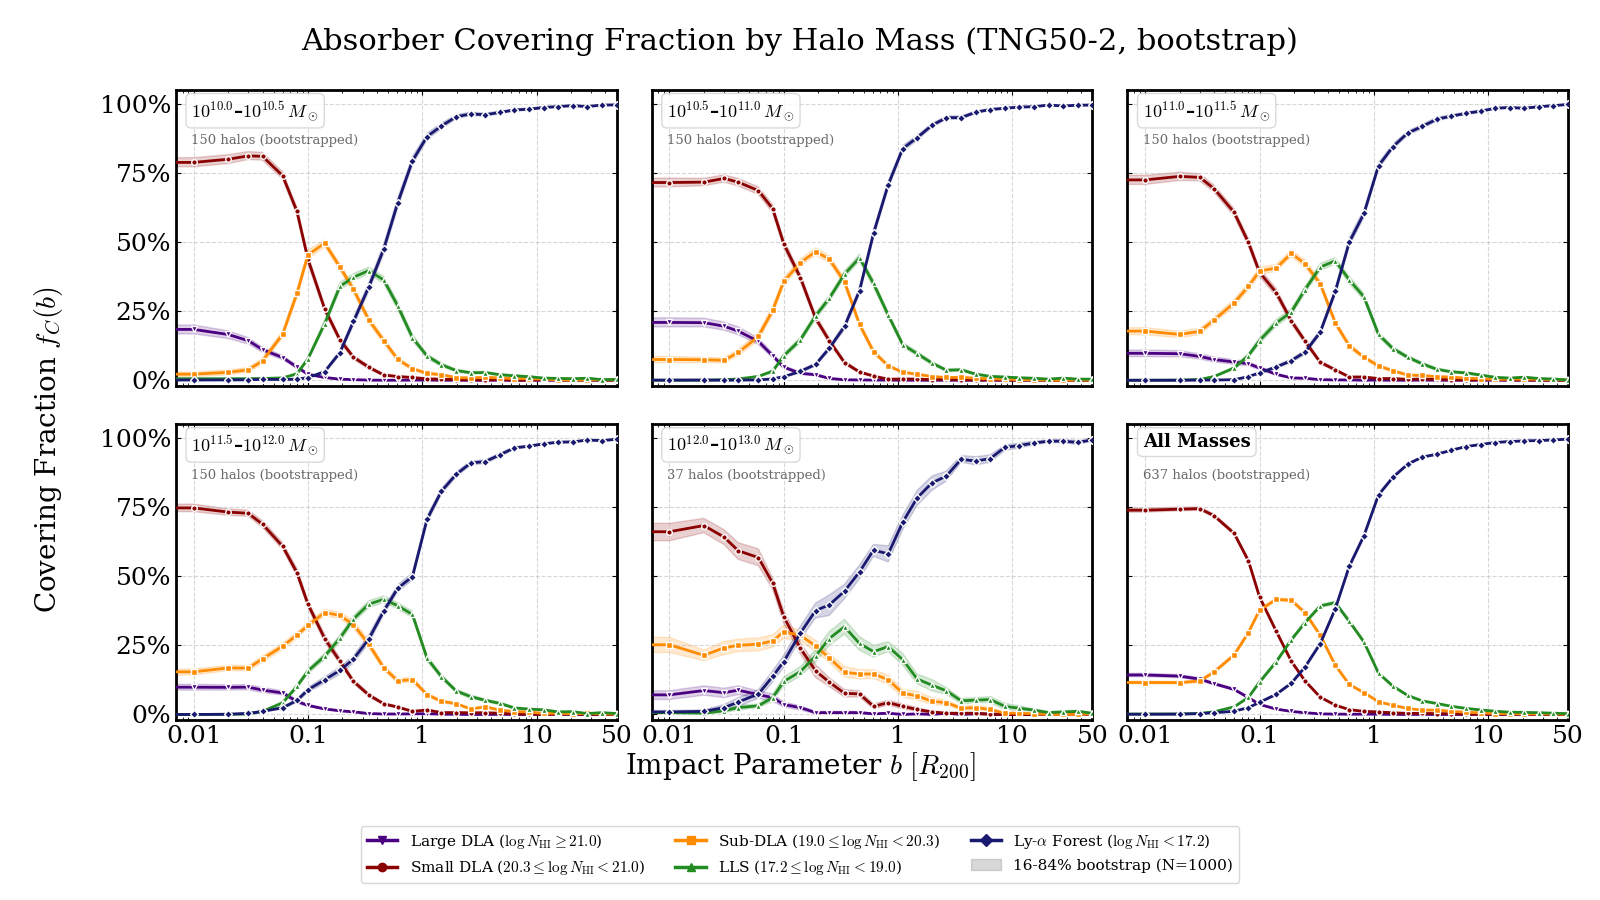

In [13]:
# ==============================================================================
# CELL: COVERING FRACTION PROFILES SPLIT BY HALO MASS BIN (bootstrap band)
# ==============================================================================
# Each panel bootstraps ONLY the halos of that mass bin -- this is what finally
# gives the exhaustive top bin (37 halos, identical across all 5 realizations
# in 10_variance_TNG50_2.ipynb) a genuine, non-degenerate uncertainty band.
panel_specs = [([bins_data_all[i]], mass_bin_titles[i]) for i in range(n_mass_bins)]
panel_specs.append((bins_data_all, 'All Masses'))

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (bd_subset, title) in zip(axes, panel_specs):
    bands = bootstrap_bands(bd_subset)
    n_halos_panel = sum(len(bd['ids']) for bd in bd_subset)

    for j, (cat, style) in enumerate(cat_styles.items()):
        central = bands['central'][:, j]
        lo, hi  = bands['lo'][:, j], bands['hi'][:, j]

        ax.fill_between(unique_radii, lo, hi, color=style['color'], alpha=0.18, zorder=1)
        ax.plot(unique_radii, central, color=style['color'], lw=2.0, ls='-',
                marker=style['marker'], ms=4, mec='white', zorder=3)

    ax.text(0.035, 0.97, title, transform=ax.transAxes, ha='left', va='top',
            fontsize=13, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.85, edgecolor='lightgray'),
            zorder=10)
    ax.text(0.035, 0.85, rf'{n_halos_panel} halos (bootstrapped)', transform=ax.transAxes,
            ha='left', va='top', fontsize=9.5, color='dimgray', zorder=10)

    ax.grid(True, ls='--', alpha=0.5)
    ax.set_xscale('log')
    ax.set_ylim(-0.02, 1.05)
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0))
    ax.set_xticks([0.01, 0.1, 1.0, 10.0, 50.0])
    ax.set_xticklabels(['0.01', '0.1', '1', '10', '50'])
    ax.set_xlim(unique_radii[unique_radii > 0].min() * 0.7, 50)

fig.supylabel(r'Covering Fraction $f_C(b)$', fontsize=20, x=0.02)
fig.suptitle(r'Absorber Covering Fraction by Halo Mass (TNG50-2, bootstrap)', fontsize=22, y=0.97)
fig.supxlabel(r'Impact Parameter $b \ [R_{200}]$', fontsize=20, y=0.13)

legend_elements = [
    Line2D([0], [0], color=c['color'], lw=2.5, marker=c['marker'], label=c['label'])
    for c in cat_styles.values()
]
legend_elements.append(
    patches.Patch(facecolor='gray', alpha=0.3, edgecolor='gray',
                  label=rf'{PCT_LO}-{PCT_HI}% bootstrap (N={N_BOOT})')
)
fig.legend(handles=legend_elements, loc='lower center', ncol=3, frameon=True, fontsize=11,
           edgecolor='lightgray', facecolor='white', framealpha=0.9, bbox_to_anchor=(0.5, 0.01))

fig.subplots_adjust(left=0.11, right=0.98, top=0.90, bottom=0.20, wspace=0.08, hspace=0.13)
plt.show()


In [14]:
# ==============================================================================
# CELL: SANITY CHECK -- does the bootstrap reproduce the 5-realization scatter?
# ==============================================================================
# If this cell's bootstrap band roughly matches the full-range band in
# 10_variance_TNG50_2.ipynb (for the four lower-mass bins, where the 5
# realizations really do draw different halos), the bootstrap is a valid,
# lower-variance replacement -- and the TODO in Sec. 2.4 of the paper resolves
# in favour of "quote the bootstrap everywhere and drop the run-x legend
# entries", per the note left there.
for j, cat in enumerate(CATS):
    lo, hi = bands_all['lo'][:, j], bands_all['hi'][:, j]
    width = hi - lo
    print(f"{cat:>10s}: median bootstrap band width = {np.nanmedian(width):.3f}")


 Large_DLA: median bootstrap band width = 0.001
 Small_DLA: median bootstrap band width = 0.003
   Sub_DLA: median bootstrap band width = 0.007
       LLS: median bootstrap band width = 0.004
    Forest: median bootstrap band width = 0.004
